In [1]:
# Load the model results exported from Notebook 2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

results_df = pd.read_csv("lettuce_choice_model_results.csv")

print("Dataset dimensions:", results_df.shape)
print("\nModel results:")
display(results_df.round(3))

Saving lettuce_consumer_choice_clean.csv to lettuce_consumer_choice_clean.csv


FileNotFoundError: [Errno 2] No such file or directory: 'lettuce_choice_model_results.csv'

In [2]:
# Recreate the confirmed model results from Notebook 2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

results_df = pd.DataFrame({
    "Variable": ["Product", "Hydro", "Organic", "Price"],
    "Coefficient": [1.225, -0.161, 0.864, -0.604],
    "Odds_Ratio": [3.405, 0.852, 2.373, 0.546],
    "OR_CI_Lower_95": [2.458, 0.720, 1.974, 0.494],
    "OR_CI_Upper_95": [4.961, 1.047, 2.780, 0.590]
})

results_df.to_csv("lettuce_choice_model_results.csv", index=False)

print("Model results ready:", results_df.shape)
display(results_df.round(3))

Model results ready: (4, 5)


,Variable,Coefficient,Odds_Ratio,OR_CI_Lower_95,OR_CI_Upper_95
0,Product,1.225,3.405,2.458,4.961
1,Hydro,-0.161,0.852,0.720,1.047
2,Organic,0.864,2.373,1.974,2.780
3,Price,-0.604,0.546,0.494,0.590


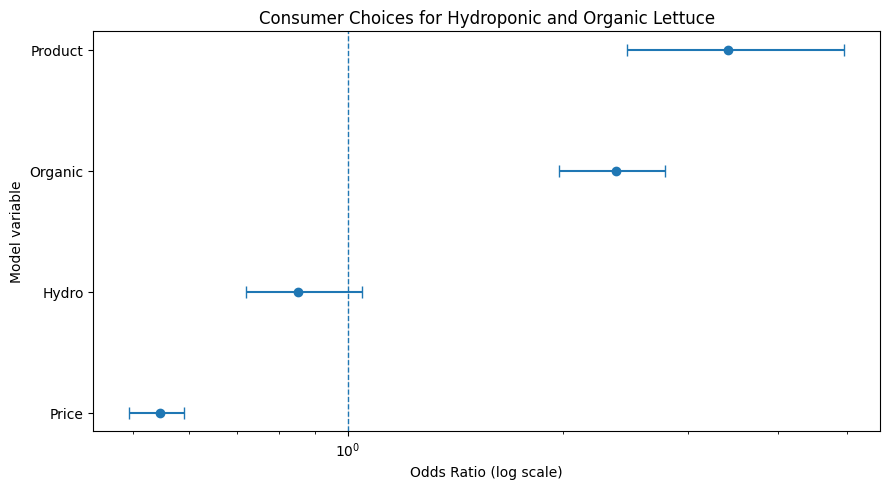

In [3]:
# Visualize odds ratios and 95% bootstrap confidence intervals
plot_df = results_df.sort_values("Odds_Ratio").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 5))

xerr = np.vstack([
    plot_df["Odds_Ratio"] - plot_df["OR_CI_Lower_95"],
    plot_df["OR_CI_Upper_95"] - plot_df["Odds_Ratio"]
])

ax.errorbar(
    plot_df["Odds_Ratio"],
    plot_df["Variable"],
    xerr=xerr,
    fmt="o",
    capsize=4
)

ax.axvline(x=1, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Odds Ratio (log scale)")
ax.set_ylabel("Model variable")
ax.set_title("Consumer Choices for Hydroponic and Organic Lettuce")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

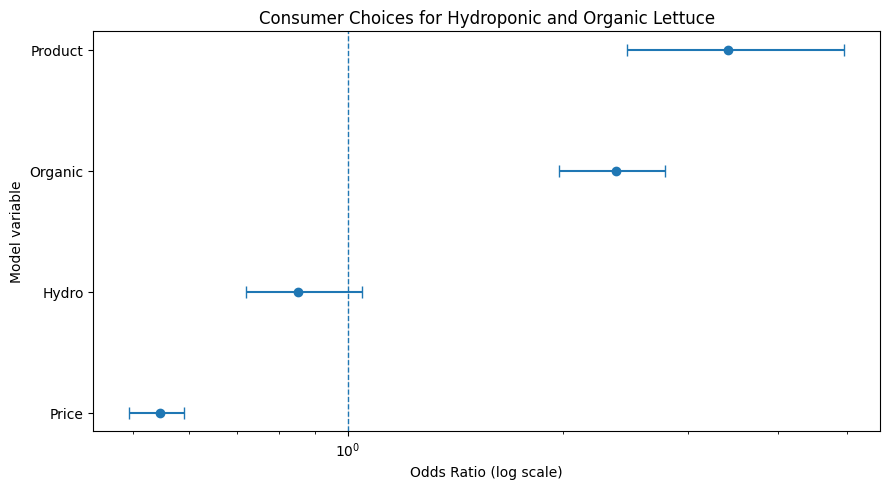

Saved: lettuce_choice_odds_ratios.png


In [4]:
# Save the forest plot for the research report
fig, ax = plt.subplots(figsize=(9, 5))

plot_df = results_df.sort_values("Odds_Ratio").reset_index(drop=True)

xerr = np.vstack([
    plot_df["Odds_Ratio"] - plot_df["OR_CI_Lower_95"],
    plot_df["OR_CI_Upper_95"] - plot_df["Odds_Ratio"]
])

ax.errorbar(
    plot_df["Odds_Ratio"],
    plot_df["Variable"],
    xerr=xerr,
    fmt="o",
    capsize=4
)

ax.axvline(x=1, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Odds Ratio (log scale)")
ax.set_ylabel("Model variable")
ax.set_title("Consumer Choices for Hydroponic and Organic Lettuce")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("lettuce_choice_odds_ratios.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: lettuce_choice_odds_ratios.png")

In [5]:
# Create a concise summary of the model findings
findings = [
    {
        "Finding": "Product vs. no purchase",
        "Result": "OR = 3.405 (95% bootstrap CI: 2.458–4.961)",
        "Interpretation": "Lettuce alternatives had higher relative selection odds than the no-purchase option."
    },
    {
        "Finding": "Organic labelling",
        "Result": "OR = 2.373 (95% bootstrap CI: 1.974–2.780)",
        "Interpretation": "Organic labelling was positively associated with relative selection odds."
    },
    {
        "Finding": "Hydroponic production",
        "Result": "OR = 0.852 (95% bootstrap CI: 0.720–1.047)",
        "Interpretation": "The confidence interval includes 1; the association was not statistically clear."
    },
    {
        "Finding": "Price",
        "Result": "OR = 0.546 (95% bootstrap CI: 0.494–0.590)",
        "Interpretation": "Higher prices were associated with lower relative selection odds."
    }
]

findings_df = pd.DataFrame(findings)
findings_df.to_csv("lettuce_choice_findings_summary.csv", index=False)

display(findings_df)
print("\nSaved: lettuce_choice_findings_summary.csv")

,Finding,Result,Interpretation
0,Product vs. no purchase,OR = 3.405 (95% bootstrap CI: 2.458–4.961),Lettuce alternatives had higher relative selec...
1,Organic labelling,OR = 2.373 (95% bootstrap CI: 1.974–2.780),Organic labelling was positively associated wi...
2,Hydroponic production,OR = 0.852 (95% bootstrap CI: 0.720–1.047),The confidence interval includes 1; the associ...
3,Price,OR = 0.546 (95% bootstrap CI: 0.494–0.590),Higher prices were associated with lower relat...



Saved: lettuce_choice_findings_summary.csv


In [6]:
# Create a concise summary of the model findings
findings = [
    {
        "Finding": "Product vs. no purchase",
        "Result": "OR = 3.405 (95% bootstrap CI: 2.458–4.961)",
        "Interpretation": "Lettuce alternatives had higher relative selection odds than the no-purchase option."
    },
    {
        "Finding": "Organic labelling",
        "Result": "OR = 2.373 (95% bootstrap CI: 1.974–2.780)",
        "Interpretation": "Organic labelling was positively associated with relative selection odds."
    },
    {
        "Finding": "Hydroponic production",
        "Result": "OR = 0.852 (95% bootstrap CI: 0.720–1.047)",
        "Interpretation": "The confidence interval includes 1; the association was not statistically clear."
    },
    {
        "Finding": "Price",
        "Result": "OR = 0.546 (95% bootstrap CI: 0.494–0.590)",
        "Interpretation": "Higher prices were associated with lower relative selection odds."
    }
]

findings_df = pd.DataFrame(findings)
findings_df.to_csv("lettuce_choice_findings_summary.csv", index=False)

display(findings_df)
print("\nSaved: lettuce_choice_findings_summary.csv")

,Finding,Result,Interpretation
0,Product vs. no purchase,OR = 3.405 (95% bootstrap CI: 2.458–4.961),Lettuce alternatives had higher relative selec...
1,Organic labelling,OR = 2.373 (95% bootstrap CI: 1.974–2.780),Organic labelling was positively associated wi...
2,Hydroponic production,OR = 0.852 (95% bootstrap CI: 0.720–1.047),The confidence interval includes 1; the associ...
3,Price,OR = 0.546 (95% bootstrap CI: 0.494–0.590),Higher prices were associated with lower relat...



Saved: lettuce_choice_findings_summary.csv


In [7]:
# Document limitations that should guide interpretation of the findings
limitations = [
    "The analysis uses a stated-choice dataset; hypothetical choices may differ from actual purchasing behaviour.",
    "The findings describe associations within the fitted model and should not automatically be interpreted as causal effects.",
    "The hydroponic estimate is uncertain because its 95% participant-bootstrap confidence interval includes an odds ratio of 1.",
    "The model assumes a linear effect of price on the log-odds scale.",
    "The results may not generalize beyond the consumers and choice scenarios represented in this dataset.",
    "The participant-level bootstrap used 200 successful replications; more replications could improve the stability of percentile confidence intervals."
]

limitations_df = pd.DataFrame({
    "Research_Limitation": limitations
})

limitations_df.to_csv("lettuce_choice_research_limitations.csv", index=False)

for number, limitation in enumerate(limitations, start=1):
    print(f"{number}. {limitation}")

print("\nSaved: lettuce_choice_research_limitations.csv")

1. The analysis uses a stated-choice dataset; hypothetical choices may differ from actual purchasing behaviour.
2. The findings describe associations within the fitted model and should not automatically be interpreted as causal effects.
3. The hydroponic estimate is uncertain because its 95% participant-bootstrap confidence interval includes an odds ratio of 1.
4. The model assumes a linear effect of price on the log-odds scale.
5. The results may not generalize beyond the consumers and choice scenarios represented in this dataset.
6. The participant-level bootstrap used 200 successful replications; more replications could improve the stability of percentile confidence intervals.

Saved: lettuce_choice_research_limitations.csv


In [8]:
# Write the final research conclusion
conclusion = """
## Research Conclusion

This study examined how hydroponic production, organic labelling, and price
were associated with consumer choices for lettuce using a stated-choice
dataset and a conditional logit model.

Organic labelling was positively associated with selection odds
(OR = 2.373, 95% participant-bootstrap CI: 1.974–2.780).
Price was negatively associated with selection odds
(OR = 0.546, 95% participant-bootstrap CI: 0.494–0.590).
The estimated association for hydroponic production was negative, but its
confidence interval included 1 (OR = 0.852, 95% participant-bootstrap CI:
0.720–1.047), so the evidence was inconclusive.

Lettuce product alternatives also had higher relative selection odds than
the no-purchase alternative (OR = 3.405, 95% participant-bootstrap CI:
2.458–4.961).

Overall, the findings suggest that organic labelling and price were important
attributes associated with stated lettuce choices in this dataset. The
hydroponic result does not establish a clear preference or disadvantage.
These findings are associations rather than proof of causal effects and
should be interpreted in light of the study's limitations.
"""

with open("lettuce_choice_research_conclusion.md", "w") as file:
    file.write(conclusion.strip())

print(conclusion)
print("\nSaved: lettuce_choice_research_conclusion.md")


## Research Conclusion

This study examined how hydroponic production, organic labelling, and price
were associated with consumer choices for lettuce using a stated-choice
dataset and a conditional logit model.

Organic labelling was positively associated with selection odds
(OR = 2.373, 95% participant-bootstrap CI: 1.974–2.780).
Price was negatively associated with selection odds
(OR = 0.546, 95% participant-bootstrap CI: 0.494–0.590).
The estimated association for hydroponic production was negative, but its
confidence interval included 1 (OR = 0.852, 95% participant-bootstrap CI:
0.720–1.047), so the evidence was inconclusive.

Lettuce product alternatives also had higher relative selection odds than
the no-purchase alternative (OR = 3.405, 95% participant-bootstrap CI:
2.458–4.961).

Overall, the findings suggest that organic labelling and price were important
attributes associated with stated lettuce choices in this dataset. The
hydroponic result does not establish a clear prefer

In [9]:
# Check which research outputs are present in the Colab session
from pathlib import Path

expected_files = [
    "lettuce_choice_model_results.csv",
    "lettuce_choice_odds_ratios.png",
    "lettuce_choice_findings_summary.csv",
    "lettuce_choice_research_limitations.csv",
    "lettuce_choice_research_conclusion.md"
]

for filename in expected_files:
    path = Path(filename)
    status = "FOUND" if path.exists() else "MISSING"

    if path.exists():
        print(f"{status}: {filename} ({path.stat().st_size:,} bytes)")
    else:
        print(f"{status}: {filename}")

FOUND: lettuce_choice_model_results.csv (185 bytes)
FOUND: lettuce_choice_odds_ratios.png (87,588 bytes)
FOUND: lettuce_choice_findings_summary.csv (586 bytes)
FOUND: lettuce_choice_research_limitations.csv (691 bytes)
FOUND: lettuce_choice_research_conclusion.md (1,159 bytes)
